**Name:** Rohan Sali

**Roll no.:** BEBD23224

## CL-2 (IR) Assignment 4: Agglomerative Hierarchical Clustering
### Implement the Agglomerative Hierarchical Clustering algorithm using an appropriate dataset.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage

plt.rcParams["figure.figsize"] = (10, 5)

In [2]:
# Use the Iris dataset as an appropriate numerical clustering dataset.
iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df["target"] = iris.target

display(df.head())
print("Dataset shape:", df.shape)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


Dataset shape: (150, 5)


In [3]:
print("Columns:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("dtype"))

print("\nMissing values:")
display(df.isna().sum().to_frame("missing"))

print("\nSummary statistics:")
display(df.describe().T)

Columns:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)', 'target']

Data types:


,dtype
sepal length (cm),float64
sepal width (cm),float64
petal length (cm),float64
petal width (cm),float64
target,int32



Missing values:


,missing
sepal length (cm),0
sepal width (cm),0
petal length (cm),0
petal width (cm),0
target,0



Summary statistics:


,count,mean,std,min,25%,50%,75%,max
sepal length (cm),150.0,5.843333,0.828066,4.3,5.1,5.80,6.4,7.9
sepal width (cm),150.0,3.057333,0.435866,2.0,2.8,3.00,3.3,4.4
petal length (cm),150.0,3.758000,1.765298,1.0,1.6,4.35,5.1,6.9
petal width (cm),150.0,1.199333,0.762238,0.1,0.3,1.30,1.8,2.5
target,150.0,1.000000,0.819232,0.0,0.0,1.00,2.0,2.0


In [4]:
X = df[iris.feature_names].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(X_scaled, columns=iris.feature_names)
display(X_scaled_df.head())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,-0.900681,1.019004,-1.340227,-1.315444
1,-1.143017,-0.131979,-1.340227,-1.315444
2,-1.385353,0.328414,-1.397064,-1.315444
3,-1.506521,0.098217,-1.283389,-1.315444
4,-1.021849,1.249201,-1.340227,-1.315444


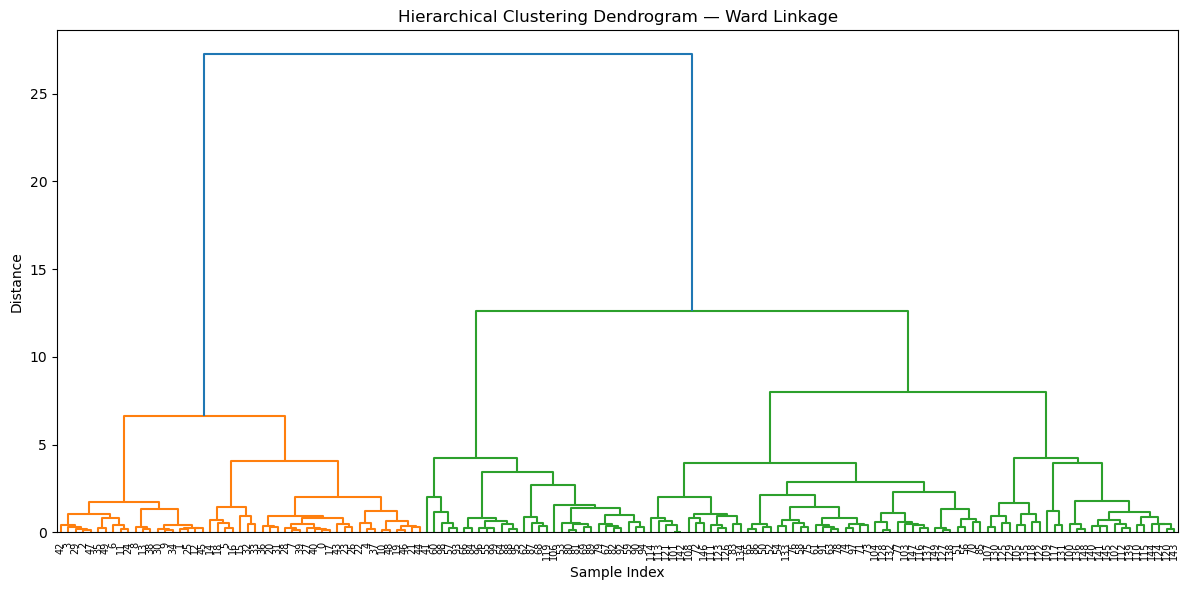

In [5]:
Z = linkage(X_scaled, method="ward")

plt.figure(figsize=(12, 6))
dendrogram(
    Z,
    labels=[str(i) for i in range(len(X_scaled))],
    leaf_rotation=90,
    leaf_font_size=7
)
plt.title("Hierarchical Clustering Dendrogram — Ward Linkage")
plt.xlabel("Sample Index")
plt.ylabel("Distance")
plt.tight_layout()
plt.show()

In [6]:
n_clusters = 3

model = AgglomerativeClustering(
    n_clusters=n_clusters,
    linkage="ward"
)

labels = model.fit_predict(X_scaled)
df["cluster"] = labels

display(df.head(10))
print("Cluster counts:")
display(df["cluster"].value_counts().sort_index())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,cluster
0,5.1,3.5,1.4,0.2,0,1
1,4.9,3.0,1.4,0.2,0,1
2,4.7,3.2,1.3,0.2,0,1
3,4.6,3.1,1.5,0.2,0,1
4,5.0,3.6,1.4,0.2,0,1
5,5.4,3.9,1.7,0.4,0,1
6,4.6,3.4,1.4,0.3,0,1
7,5.0,3.4,1.5,0.2,0,1
8,4.4,2.9,1.4,0.2,0,1
9,4.9,3.1,1.5,0.1,0,1


Cluster counts:


cluster
0    71
1    49
2    30
Name: count, dtype: int64

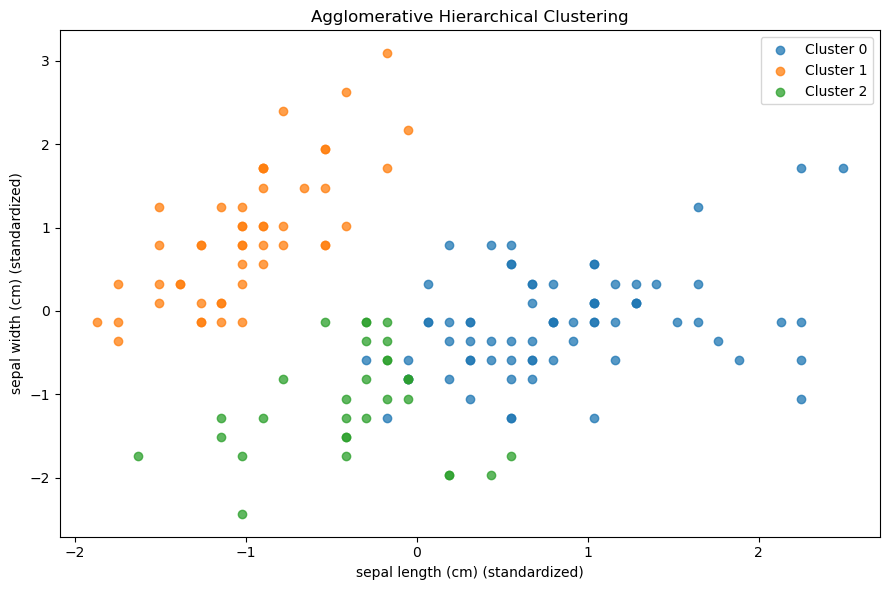

In [7]:
# Visualize using the first two standardized features.
plt.figure(figsize=(9, 6))

for cluster_id in sorted(df["cluster"].unique()):
    mask = df["cluster"] == cluster_id
    plt.scatter(
        X_scaled[mask, 0],
        X_scaled[mask, 1],
        label=f"Cluster {cluster_id}",
        alpha=0.75
    )

plt.title("Agglomerative Hierarchical Clustering")
plt.xlabel(iris.feature_names[0] + " (standardized)")
plt.ylabel(iris.feature_names[1] + " (standardized)")
plt.legend()
plt.tight_layout()
plt.show()

In [8]:
silhouette = silhouette_score(X_scaled, labels)
print(f"Silhouette Score: {silhouette:.4f}")

Silhouette Score: 0.4467


In [9]:
cluster_summary = df.groupby("cluster")[iris.feature_names].mean()
display(cluster_summary)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
cluster,,,,
0,6.546479,2.992958,5.267606,1.854930
1,5.016327,3.451020,1.465306,0.244898
2,5.530000,2.566667,3.930000,1.206667
